# KNN & PCA — Assignment Solutions  
---

## Part A: Theoretical Questions (Q1 – Q20)


### 1. What is K-Nearest Neighbors (KNN) and how does it work?
**Answer:**  
**K-Nearest Neighbors (KNN)** is a non-parametric, instance-based (lazy learning) supervised machine learning algorithm used for both classification and regression.

**How it works:**
1. Stores the entire training dataset in memory during the training phase (no explicit parameter learning).
2. For a new query point, computes the distance between the query point and all training points using a chosen distance metric (e.g., Euclidean).
3. Selects the $K$ closest training samples (nearest neighbors).
4. Aggregates their target values—using **majority voting** for classification or **averaging** for regression—to produce the prediction.


### 2. What is the difference between KNN Classification and KNN Regression?
**Answer:**  
- **KNN Classification:** Predicts a **discrete class label** by taking a majority vote (or distance-weighted vote) among the $K$ nearest neighbors.
- **KNN Regression:** Predicts a **continuous numerical value** by calculating the arithmetic mean (or inverse-distance weighted average) of the target values of the $K$ nearest neighbors.


### 3. What is the role of the distance metric in KNN?
**Answer:**  
The **distance metric** defines how similarity or closeness between data points is measured in feature space. Choosing the right metric directly determines which $K$ points are considered "nearest":
- **Euclidean Distance ($L_2$):** Straight-line distance; best for continuous, dense, scaled numeric features.
- **Manhattan Distance ($L_1$):** Sum of absolute coordinate differences; robust to outliers and grid-like/high-dimensional spaces.
- **Minkowski Distance:** Generalizes both $L_1$ ($p=1$) and $L_2$ ($p=2$).
- **Cosine / Hamming Distance:** Used for text embeddings or categorical/binary features.


### 4. What is the Curse of Dimensionality in KNN?
**Answer:**  
As the number of features (dimensions $d$) grows very large, feature space volume expands exponentially and data points become sparse. Consequently, the distance between the nearest neighbor and the farthest point converges toward the same value ($\text{dist}_{\max} \approx \text{dist}_{\min}$), making Euclidean distance meaningless and degrading KNN's predictive accuracy while increasing computation cost.


### 5. How can we choose the best value of K in KNN?
**Answer:**  
- **Cross-Validation / GridSearchCV:** Evaluate validation error or accuracy across a range of $K$ values (e.g., $K = 1, 3, 5, \dots, 31$) and pick the $K$ with the lowest validation error.
- **Rule of Thumb:** Start near $K \approx \sqrt{N}$ (where $N$ is the number of training samples).
- **Odd $K$ for Binary Classification:** Use an odd integer to prevent tie votes.
- **Bias-Variance Trade-off:** Very small $K$ (e.g., $K=1$) has low bias but high variance (sensitive to noise); very large $K$ smooths boundaries too much (high bias, underfitting).


### 6. What are KD Tree and Ball Tree in KNN?
**Answer:**  
Both are spatial partitioning data structures designed to accelerate nearest-neighbor searches from $O(N)$ brute-force scans down to $O(\log N)$ on average:
- **KD Tree (K-Dimensional Tree):** A binary tree that recursively splits feature space along axis-aligned hyperplanes (median splits along alternating coordinate axes).
- **Ball Tree:** Partitions data into a hierarchy of nested hyperspheres ("balls") defined by a center and radius, using triangle inequality to prune distant branches.


### 7. When should you use KD Tree vs. Ball Tree?
**Answer:**  
- **Use KD Tree:** When dimensionality is low ($d < 20$) and using standard axis-aligned metrics like Euclidean or Manhattan distance.
- **Use Ball Tree:** In moderate-to-high dimensions ($d \ge 20$) where KD Trees degrade toward brute-force speed, or when using non-axis-aligned / custom distance metrics (e.g., Haversine, Cosine).


### 8. What are the disadvantages of KNN?
**Answer:**  
- **Slow Prediction Time ($O(N \cdot d)$):** Computes distances against every training sample at inference time.
- **High Memory Footprint:** Must retain the entire training dataset in RAM.
- **Sensitivity to Feature Scale & Irrelevant Features:** Unscaled or noisy features distort distance calculations.
- **Curse of Dimensionality:** Performance drops sharply in high-dimensional spaces.


### 9. How does feature scaling affect KNN?
**Answer:**  
Because KNN relies directly on geometric distances between points, features with larger numeric ranges (e.g., salary in lakhs vs. age in years) dominate the distance calculation. Applying `StandardScaler` or `MinMaxScaler` puts all features on an equal footing, preventing any single variable from skewing neighbor selection.


### 10. What is PCA (Principal Component Analysis)?
**Answer:**  
**Principal Component Analysis (PCA)** is an unsupervised linear dimensionality reduction technique that transforms a set of possibly correlated features into a smaller set of linearly uncorrelated variables called **Principal Components (PCs)**, ordered so that the first few components capture the maximum possible variance from the original dataset.


### 11. How does PCA work?
**Answer:**  
1. **Standardize the Data:** Center features to mean $0$ and unit variance ($Z = \frac{X - \mu}{\sigma}$).
2. **Compute the Covariance Matrix:** Calculate $\Sigma = \frac{1}{n-1} Z^T Z$ to capture pairwise feature correlations.
3. **Eigen Decomposition (or SVD):** Compute the eigenvalues and eigenvectors of $\Sigma$.
4. **Sort & Select Top $k$ Components:** Rank eigenvectors by descending eigenvalues and select the top $k$ eigenvectors forming projection matrix $W$.
5. **Project Data:** Transform original data onto the new subspace via $Z_{\text{new}} = Z W$.


### 12. What is the geometric intuition behind PCA?
**Answer:**  
Geometrically, PCA rotates the original coordinate axes to align with the directions along which the data cloud stretches the most (maximum variance):
- **PC1** is the line through the data centroid that maximizes the variance of projected points (equivalently minimizing orthogonal projection residuals).
- **PC2** is the orthogonal axis perpendicular to PC1 that captures the next highest remaining variance, and so forth.


### 13. What is the difference between Feature Selection and Feature Extraction?
**Answer:**  
- **Feature Selection:** Chooses a **subset of the original features** without altering their values (e.g., removing low-variance or redundant columns via SelectKBest or RFE). Preserves original feature interpretability.
- **Feature Extraction:** Creates **new, lower-dimensional features** by mathematically combining or transforming existing ones (e.g., PCA, LDA, t-SNE).


### 14. What are Eigenvalues and Eigenvectors in PCA?
**Answer:**  
- **Eigenvectors:** Unit vectors defining the **directions** of the new orthogonal axes (the Principal Components) in feature space.
- **Eigenvalues:** Scalar magnitudes associated with each eigenvector representing the **amount of variance** captured along that Principal Component. Dividing an eigenvalue by the sum of all eigenvalues gives its **Explained Variance Ratio**.


### 15. How do you decide the number of components to keep in PCA?
**Answer:**  
1. **Cumulative Explained Variance Threshold:** Retain the smallest number of components $k$ that capture a target percentage of total variance (typically **90%–95%**).
2. **Scree Plot (Elbow Method):** Plot eigenvalues against component index and stop at the "elbow" where marginal variance gain flattens.
3. **Kaiser Criterion:** Keep components with eigenvalues $\lambda > 1$ (for standardized data).
4. **Downstream Cross-Validation:** Tune `n_components` directly inside a supervised pipeline (e.g., PCA + KNN) using GridSearchCV.


### 16. Can PCA be used for classification?
**Answer:**  
PCA itself is an **unsupervised** transformation algorithm—it does not output class labels directly. However, it is widely used as a **preprocessing step before a classifier** (such as KNN, Logistic Regression, or SVM) to remove multicollinearity, filter noise, speed up training, and mitigate the curse of dimensionality.


### 17. What are the limitations of PCA?
**Answer:**  
- **Linearity Assumption:** Only captures linear correlations; fails on curved/non-linear manifolds (where Kernel PCA or t-SNE/UMAP is needed).
- **Loss of Interpretability:** Principal components are linear combinations of all features, making domain interpretation harder.
- **Scale Sensitivity:** Requires careful feature standardization beforehand.
- **Unsupervised Objective:** Maximizes variance rather than class separability, so directions of highest variance may not align with class boundaries.


### 18. How do KNN and PCA complement each other?
**Answer:**  
KNN suffers severely from the **Curse of Dimensionality**, noisy features, and slow distance computations in high-dimensional spaces. Applying **PCA prior to KNN** projects data into a compact, noise-filtered, orthogonal lower-dimensional subspace—simultaneously improving KNN's distance reliability, boosting classification accuracy, and accelerating neighbor search.


### 19. How does KNN handle missing values in a dataset?
**Answer:**  
Standard KNN cannot natively compute Euclidean distances when `NaN` values exist. However, **KNN Imputation (`KNNImputer`)** handles missing data by finding the $K$ nearest complete/comparable neighbors using distances computed over available non-missing features, and imputing the missing entry with the mean (or distance-weighted mean) of those neighbors.


### 20. What are the key differences between PCA and Linear Discriminant Analysis (LDA)?
**Answer:**  
| Aspect | PCA | LDA |
|---|---|---|
| **Learning Type** | **Unsupervised** (ignores class labels) | **Supervised** (uses class labels $y$) |
| **Objective** | Maximizes total **data variance** | Maximizes **between-class separation** while minimizing within-class scatter |
| **Max Components** | Up to $\min(n_{\text{samples}}, n_{\text{features}})$ | At most $C - 1$ (where $C$ is the number of classes) |
| **Primary Use Case** | General compression, noise removal, visualization | Supervised feature extraction for classification |


---

## Part B: Practical Questions (Q21 – Q48)

Run the setup cell below first to import required libraries and datasets so every cell executes cleanly in Google Colab.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_wine, load_breast_cancer, make_classification, make_regression, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, mean_squared_error, classification_report,
    precision_score, recall_score, f1_score, roc_auc_score
)

sns.set_theme(style="whitegrid")
print("Environment initialized successfully!")


Environment initialized successfully!


### 21. Train a KNN Classifier on the Iris dataset and print model accuracy.


In [2]:
iris = load_iris()
Xi_train, Xi_test, yi_train, yi_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)

knn21 = KNeighborsClassifier(n_neighbors=5)
knn21.fit(Xi_train, yi_train)
print(f"Q21 - KNN Classifier Accuracy (Iris): {accuracy_score(yi_test, knn21.predict(Xi_test)):.4f}")


Q21 - KNN Classifier Accuracy (Iris): 1.0000


### 22. Train a KNN Regressor on a synthetic dataset and evaluate using Mean Squared Error (MSE).


In [3]:
Xr, yr = make_regression(n_samples=500, n_features=8, noise=12.0, random_state=42)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

knn_reg22 = KNeighborsRegressor(n_neighbors=5)
knn_reg22.fit(Xr_train, yr_train)
print(f"Q22 - KNN Regressor MSE: {mean_squared_error(yr_test, knn_reg22.predict(Xr_test)):.4f}")


Q22 - KNN Regressor MSE: 4883.0821


### 23. Train a KNN Classifier using different distance metrics (Euclidean and Manhattan) and compare accuracy.


In [4]:
cancer = load_breast_cancer()
Xc_train, Xc_test, yc_train, yc_test = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=42)
scaler = StandardScaler()
Xc_tr_s = scaler.fit_transform(Xc_train)
Xc_te_s = scaler.transform(Xc_test)

for metric in ['euclidean', 'manhattan']:
    clf = KNeighborsClassifier(n_neighbors=5, metric=metric).fit(Xc_tr_s, yc_train)
    print(f"Q23 - Metric: {metric:9s} -> Accuracy: {accuracy_score(yc_test, clf.predict(Xc_te_s)):.4f}")


Q23 - Metric: euclidean -> Accuracy: 0.9474
Q23 - Metric: manhattan -> Accuracy: 0.9649


### 24. Train a KNN Classifier with different values of $K$ and visualize decision boundaries.


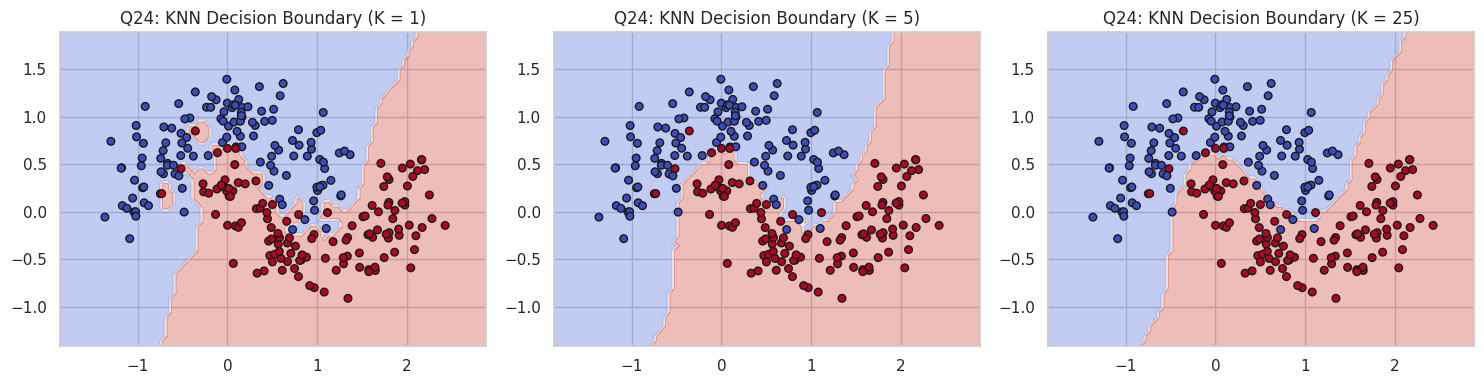

In [5]:
X24, y24 = make_moons(n_samples=250, noise=0.22, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

h = 0.05
x_min, x_max = X24[:, 0].min() - 0.5, X24[:, 0].max() + 0.5
y_min, y_max = X24[:, 1].min() - 0.5, X24[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

for ax, k in zip(axes, [1, 5, 25]):
    clf = KNeighborsClassifier(n_neighbors=k).fit(X24, y24)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.35, cmap='coolwarm')
    ax.scatter(X24[:, 0], X24[:, 1], c=y24, cmap='coolwarm', edgecolor='k', s=30)
    ax.set_title(f"Q24: KNN Decision Boundary (K = {k})")

plt.tight_layout()
plt.show()


### 25. Apply Feature Scaling before training a KNN model and compare results with unscaled data.


In [6]:
wine = load_wine()
Xw_train, Xw_test, yw_train, yw_test = train_test_split(wine.data, wine.target, test_size=0.25, random_state=42)

knn_unscaled = KNeighborsClassifier(n_neighbors=5).fit(Xw_train, yw_train)
acc_unscaled = accuracy_score(yw_test, knn_unscaled.predict(Xw_test))

Xw_tr_s = scaler.fit_transform(Xw_train)
Xw_te_s = scaler.transform(Xw_test)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(Xw_tr_s, yw_train)
acc_scaled = accuracy_score(yw_test, knn_scaled.predict(Xw_te_s))

print(f"Q25 - Unscaled Wine Accuracy: {acc_unscaled:.4f}")
print(f"Q25 - Scaled Wine Accuracy:   {acc_scaled:.4f}")


Q25 - Unscaled Wine Accuracy: 0.7111
Q25 - Scaled Wine Accuracy:   0.9556


### 26. Train a PCA model on synthetic data and print the explained variance ratio for each component.


In [7]:
X26, _ = make_classification(n_samples=300, n_features=6, n_informative=4, random_state=42)
X26_scaled = StandardScaler().fit_transform(X26)

pca26 = PCA()
pca26.fit(X26_scaled)
for idx, ratio in enumerate(pca26.explained_variance_ratio_, 1):
    print(f"Q26 - PC{idx} Explained Variance Ratio: {ratio:.4f}")


Q26 - PC1 Explained Variance Ratio: 0.5467
Q26 - PC2 Explained Variance Ratio: 0.2060
Q26 - PC3 Explained Variance Ratio: 0.1596
Q26 - PC4 Explained Variance Ratio: 0.0877
Q26 - PC5 Explained Variance Ratio: 0.0000
Q26 - PC6 Explained Variance Ratio: 0.0000


### 27. Apply PCA before training a KNN Classifier and compare accuracy with and without PCA.


In [8]:
knn_no_pca = KNeighborsClassifier(n_neighbors=5).fit(Xc_tr_s, yc_train)
acc_no_pca = accuracy_score(yc_test, knn_no_pca.predict(Xc_te_s))

pca27 = PCA(n_components=5, random_state=42)
Xc_tr_pca = pca27.fit_transform(Xc_tr_s)
Xc_te_pca = pca27.transform(Xc_te_s)
knn_pca = KNeighborsClassifier(n_neighbors=5).fit(Xc_tr_pca, yc_train)
acc_pca = accuracy_score(yc_test, knn_pca.predict(Xc_te_pca))

print(f"Q27 - KNN Accuracy WITHOUT PCA (30 features): {acc_no_pca:.4f}")
print(f"Q27 - KNN Accuracy WITH PCA (5 components):   {acc_pca:.4f}")


Q27 - KNN Accuracy WITHOUT PCA (30 features): 0.9474
Q27 - KNN Accuracy WITH PCA (5 components):   0.9561


### 28. Perform Hyperparameter Tuning on a KNN Classifier using `GridSearchCV`.


In [9]:
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
grid_knn.fit(Xc_tr_s, yc_train)

print(f"Q28 - Best Parameters:  {grid_knn.best_params_}")
print(f"Q28 - Best CV Accuracy: {grid_knn.best_score_:.4f}")
print(f"Q28 - Test Accuracy:    {accuracy_score(yc_test, grid_knn.best_estimator_.predict(Xc_te_s)):.4f}")


Q28 - Best Parameters:  {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'}
Q28 - Best CV Accuracy: 0.9648
Q28 - Test Accuracy:    0.9649


### 29. Train a KNN Classifier and check the number of misclassified samples.


In [10]:
preds29 = knn21.predict(Xi_test)
misclassified_count = np.sum(preds29 != yi_test)
print(f"Q29 - Total Test Samples: {len(yi_test)} | Misclassified Samples: {misclassified_count}")


Q29 - Total Test Samples: 30 | Misclassified Samples: 0


### 30. Train a PCA model and visualize the cumulative explained variance.


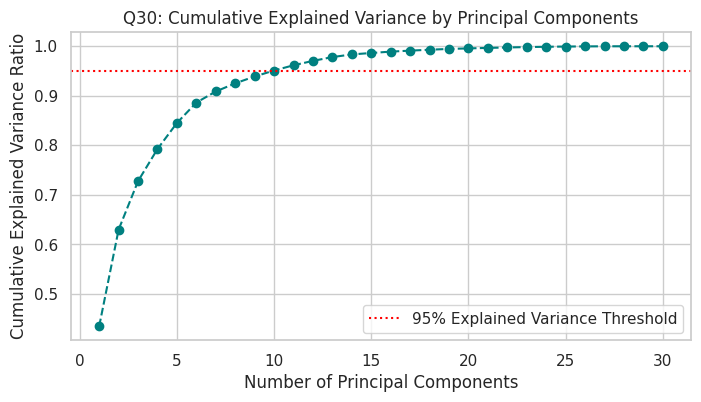

In [11]:
pca30 = PCA().fit(Xc_tr_s)
cum_var = np.cumsum(pca30.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--', color='teal')
plt.axhline(y=0.95, color='red', linestyle=':', label='95% Explained Variance Threshold')
plt.title("Q30: Cumulative Explained Variance by Principal Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.legend()
plt.show()


### 31. Train a KNN Classifier using different values of the `weights` parameter (`uniform` vs. `distance`) and compare accuracy.


In [12]:
for w in ['uniform', 'distance']:
    clf_w = KNeighborsClassifier(n_neighbors=7, weights=w).fit(Xc_tr_s, yc_train)
    print(f"Q31 - weights='{w:8s}' -> Test Accuracy: {accuracy_score(yc_test, clf_w.predict(Xc_te_s)):.4f}")


Q31 - weights='uniform ' -> Test Accuracy: 0.9474
Q31 - weights='distance' -> Test Accuracy: 0.9474


### 32. Train a KNN Regressor and analyze the effect of different $K$ values on performance.


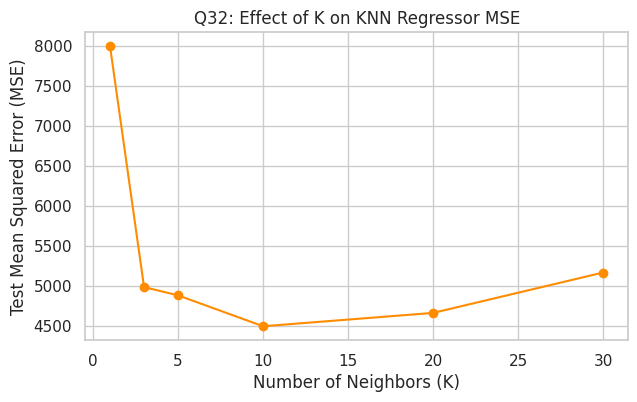

In [13]:
k_vals32 = [1, 3, 5, 10, 20, 30]
mses32 = []
for k in k_vals32:
    reg = KNeighborsRegressor(n_neighbors=k).fit(Xr_train, yr_train)
    mses32.append(mean_squared_error(yr_test, reg.predict(Xr_test)))

plt.figure(figsize=(7, 4))
plt.plot(k_vals32, mses32, marker='o', color='darkorange')
plt.title("Q32: Effect of K on KNN Regressor MSE")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Mean Squared Error (MSE)")
plt.show()


### 33. Implement KNN Imputation for handling missing values in a dataset.


In [14]:
X_missing = iris.data.copy()
rng = np.random.default_rng(42)
mask = rng.random(X_missing.shape) < 0.15
X_missing[mask] = np.nan

print(f"Q33 - Missing values before imputation: {np.isnan(X_missing).sum()}")
imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(X_missing)
print(f"Q33 - Missing values after KNNImputer:  {np.isnan(X_imputed).sum()}")


Q33 - Missing values before imputation: 101
Q33 - Missing values after KNNImputer:  0


### 34. Train a PCA model and visualize the data projection onto the first two principal components.


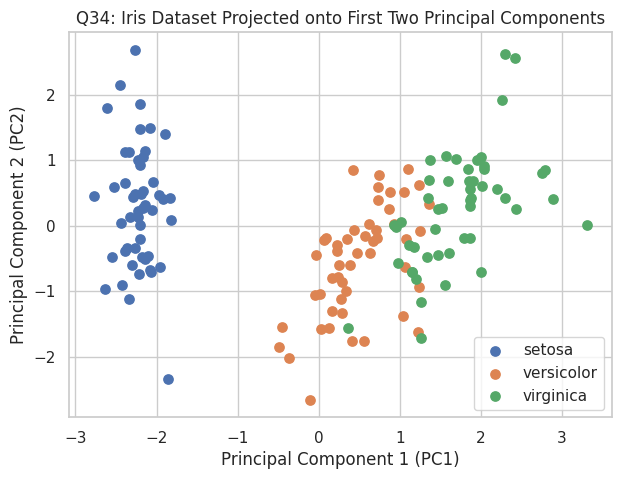

In [15]:
Xi_scaled = StandardScaler().fit_transform(iris.data)
Xi_pca2 = PCA(n_components=2).fit_transform(Xi_scaled)

plt.figure(figsize=(7, 5))
for idx, target_name in enumerate(iris.target_names):
    plt.scatter(Xi_pca2[iris.target == idx, 0], Xi_pca2[iris.target == idx, 1], label=target_name, s=45)
plt.title("Q34: Iris Dataset Projected onto First Two Principal Components")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend()
plt.show()


### 35. Train a KNN Classifier using the `kd_tree` and `ball_tree` algorithms and compare performance.


In [16]:
import time
for algo in ['kd_tree', 'ball_tree']:
    t0 = time.time()
    clf_algo = KNeighborsClassifier(n_neighbors=5, algorithm=algo).fit(Xc_tr_s, yc_train)
    acc = accuracy_score(yc_test, clf_algo.predict(Xc_te_s))
    elapsed = (time.time() - t0) * 1000
    print(f"Q35 - Algorithm: {algo:9s} -> Accuracy: {acc:.4f} | Time: {elapsed:.2f} ms")


Q35 - Algorithm: kd_tree   -> Accuracy: 0.9474 | Time: 14.43 ms
Q35 - Algorithm: ball_tree -> Accuracy: 0.9474 | Time: 10.27 ms


### 36. Train a PCA model on a high-dimensional dataset and visualize the Scree plot.


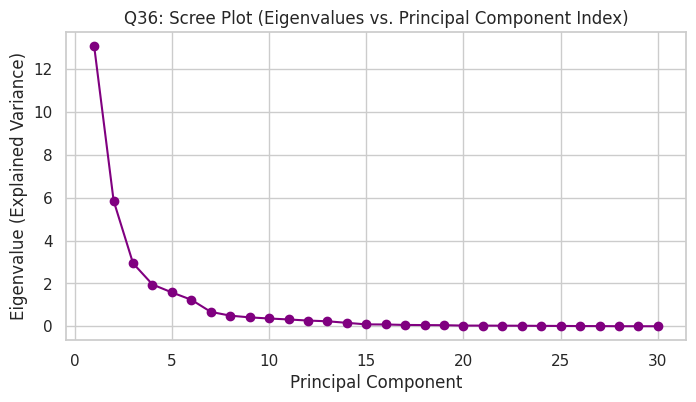

In [17]:
pca36 = PCA().fit(Xc_tr_s)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(pca36.explained_variance_) + 1), pca36.explained_variance_, marker='o', color='purple')
plt.title("Q36: Scree Plot (Eigenvalues vs. Principal Component Index)")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue (Explained Variance)")
plt.show()


### 37. Train a KNN Classifier and evaluate performance using Precision, Recall, and F1-Score.


In [18]:
y_pred37 = knn_scaled.predict(Xw_te_s)
print(f"Q37 - Weighted Precision: {precision_score(yw_test, y_pred37, average='weighted'):.4f}")
print(f"Q37 - Weighted Recall:    {recall_score(yw_test, y_pred37, average='weighted'):.4f}")
print(f"Q37 - Weighted F1-Score:  {f1_score(yw_test, y_pred37, average='weighted'):.4f}")


Q37 - Weighted Precision: 0.9587
Q37 - Weighted Recall:    0.9556
Q37 - Weighted F1-Score:  0.9551


### 38. Train a PCA model and analyze the effect of different numbers of components on accuracy.


In [19]:
print("Q38 - KNN Accuracy across varying PCA component counts:")
for n_comp in [2, 5, 10, 15, 20, 30]:
    pca_tmp = PCA(n_components=n_comp, random_state=42)
    X_tr_p = pca_tmp.fit_transform(Xc_tr_s)
    X_te_p = pca_tmp.transform(Xc_te_s)
    acc = accuracy_score(yc_test, KNeighborsClassifier(n_neighbors=5).fit(X_tr_p, yc_train).predict(X_te_p))
    print(f"  n_components = {n_comp:2d} -> KNN Accuracy: {acc:.4f}")


Q38 - KNN Accuracy across varying PCA component counts:
  n_components =  2 -> KNN Accuracy: 0.9737
  n_components =  5 -> KNN Accuracy: 0.9561
  n_components = 10 -> KNN Accuracy: 0.9561
  n_components = 15 -> KNN Accuracy: 0.9474
  n_components = 20 -> KNN Accuracy: 0.9474
  n_components = 30 -> KNN Accuracy: 0.9474


### 39. Train a KNN Classifier with different `leaf_size` values and compare accuracy.


In [20]:
print("Q39 - KNN Accuracy across different leaf_size values:")
for leaf in [5, 15, 30, 50, 100]:
    clf_leaf = KNeighborsClassifier(n_neighbors=5, leaf_size=leaf).fit(Xc_tr_s, yc_train)
    print(f"  leaf_size = {leaf:3d} -> Accuracy: {accuracy_score(yc_test, clf_leaf.predict(Xc_te_s)):.4f}")


Q39 - KNN Accuracy across different leaf_size values:
  leaf_size =   5 -> Accuracy: 0.9474
  leaf_size =  15 -> Accuracy: 0.9474
  leaf_size =  30 -> Accuracy: 0.9474
  leaf_size =  50 -> Accuracy: 0.9474
  leaf_size = 100 -> Accuracy: 0.9474


### 40. Train a PCA model and visualize how data points are transformed before and after PCA.


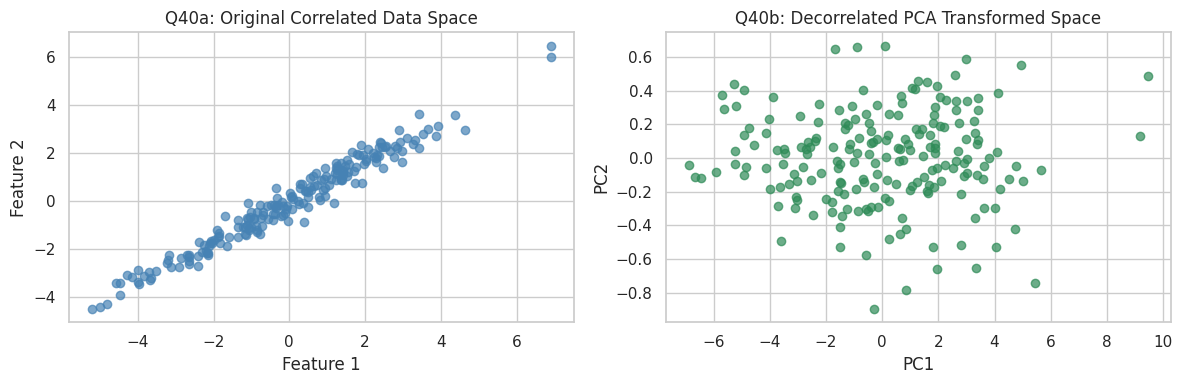

In [21]:
rng40 = np.random.default_rng(42)
X40 = rng40.normal(size=(200, 2)) @ np.array([[2.0, 1.5], [1.0, 1.2]])
X40_pca = PCA(n_components=2).fit_transform(X40)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X40[:, 0], X40[:, 1], alpha=0.7, color='steelblue')
axes[0].set_title("Q40a: Original Correlated Data Space")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

axes[1].scatter(X40_pca[:, 0], X40_pca[:, 1], alpha=0.7, color='seagreen')
axes[1].set_title("Q40b: Decorrelated PCA Transformed Space")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()


### 41. Train a KNN Classifier on a real-world dataset (Wine dataset) and print classification report.


In [22]:
print("Q41 - Classification Report (Wine Dataset):")
print(classification_report(yw_test, y_pred37, target_names=wine.target_names))


Q41 - Classification Report (Wine Dataset):
              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.89      0.94        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.96        45
   macro avg       0.95      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



### 42. Train a KNN Regressor and analyze the effect of different distance metrics on prediction error.


In [23]:
Xr_tr_s = scaler.fit_transform(Xr_train)
Xr_te_s = scaler.transform(Xr_test)

for metric in ['euclidean', 'manhattan', 'chebyshev']:
    reg_m = KNeighborsRegressor(n_neighbors=5, metric=metric).fit(Xr_tr_s, yr_train)
    mse_m = mean_squared_error(yr_test, reg_m.predict(Xr_te_s))
    print(f"Q42 - Metric: {metric:9s} -> Regressor MSE: {mse_m:.4f}")


Q42 - Metric: euclidean -> Regressor MSE: 4719.6638
Q42 - Metric: manhattan -> Regressor MSE: 4682.8090
Q42 - Metric: chebyshev -> Regressor MSE: 4961.6746


### 43. Train a KNN Classifier and evaluate using ROC-AUC score.


In [24]:
knn_auc = KNeighborsClassifier(n_neighbors=7).fit(Xc_tr_s, yc_train)
y_probs43 = knn_auc.predict_proba(Xc_te_s)[:, 1]
print(f"Q43 - KNN Classifier ROC-AUC Score (Breast Cancer): {roc_auc_score(yc_test, y_probs43):.4f}")


Q43 - KNN Classifier ROC-AUC Score (Breast Cancer): 0.9805


### 44. Train a PCA model and visualize the variance captured by each principal component.


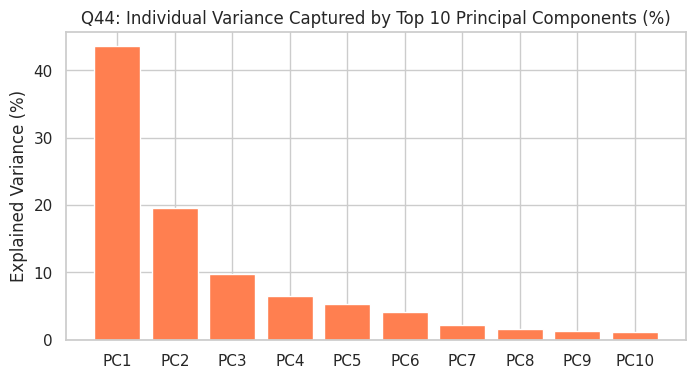

In [25]:
pca44 = PCA(n_components=10).fit(Xc_tr_s)
plt.figure(figsize=(8, 4))
plt.bar([f"PC{i}" for i in range(1, 11)], pca44.explained_variance_ratio_ * 100, color='coral')
plt.title("Q44: Individual Variance Captured by Top 10 Principal Components (%)")
plt.ylabel("Explained Variance (%)")
plt.show()


### 45. Train a KNN Classifier and perform feature selection before training.


In [26]:
selector = SelectKBest(score_func=f_classif, k=10)
Xc_tr_sel = selector.fit_transform(Xc_tr_s, yc_train)
Xc_te_sel = selector.transform(Xc_te_s)

knn_sel = KNeighborsClassifier(n_neighbors=5).fit(Xc_tr_sel, yc_train)
print(f"Q45 - KNN Accuracy after SelectKBest (Top 10 Features): {accuracy_score(yc_test, knn_sel.predict(Xc_te_sel)):.4f}")


Q45 - KNN Accuracy after SelectKBest (Top 10 Features): 0.9737


### 46. Train a PCA model and visualize the data reconstruction error after reducing dimensions.


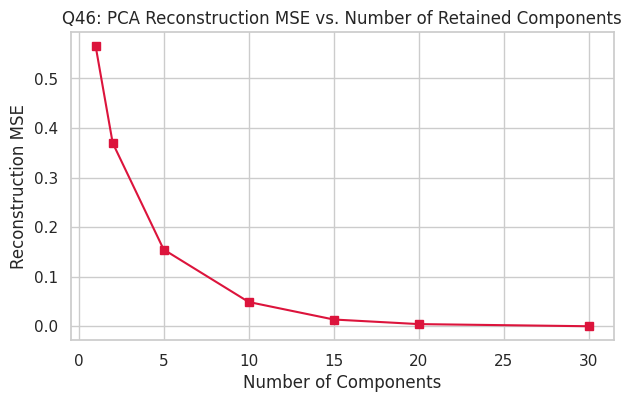

In [27]:
comp_list46 = [1, 2, 5, 10, 15, 20, 30]
recon_errors = []

for c in comp_list46:
    pca_r = PCA(n_components=c, random_state=42)
    Z_reduced = pca_r.fit_transform(Xc_tr_s)
    X_reconstructed = pca_r.inverse_transform(Z_reduced)
    recon_errors.append(mean_squared_error(Xc_tr_s, X_reconstructed))

plt.figure(figsize=(7, 4))
plt.plot(comp_list46, recon_errors, marker='s', color='crimson')
plt.title("Q46: PCA Reconstruction MSE vs. Number of Retained Components")
plt.xlabel("Number of Components")
plt.ylabel("Reconstruction MSE")
plt.show()


### 47. Train a KNN Classifier and visualize the decision boundary.


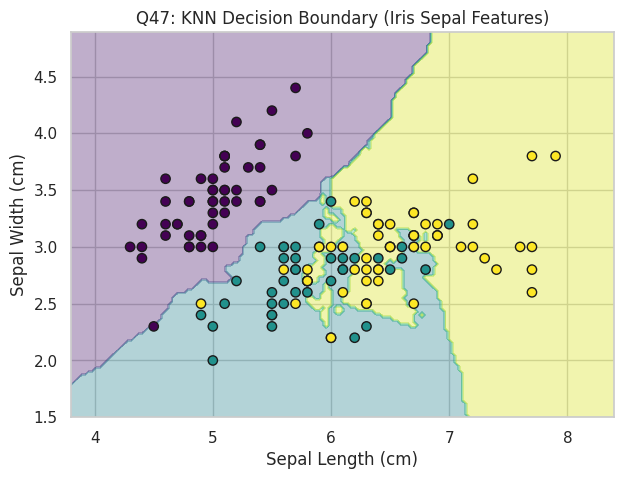

In [28]:
X47 = iris.data[:, :2]
y47 = iris.target
knn47 = KNeighborsClassifier(n_neighbors=5).fit(X47, y47)

x_min, x_max = X47[:, 0].min() - 0.5, X47[:, 0].max() + 0.5
y_min, y_max = X47[:, 1].min() - 0.5, X47[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.03), np.arange(y_min, y_max, 0.03))
Z47 = knn47.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z47, alpha=0.35, cmap='viridis')
plt.scatter(X47[:, 0], X47[:, 1], c=y47, cmap='viridis', edgecolor='k', s=45)
plt.title("Q47: KNN Decision Boundary (Iris Sepal Features)")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.show()


### 48. Train a PCA model and analyze the effect of different numbers of components on data variance.


In [29]:
print("Q48 - Cumulative Data Variance Retained across Component Counts:")
for k_comp in [1, 2, 3, 5, 10, 15, 20]:
    var_retained = PCA(n_components=k_comp).fit(Xc_tr_s).explained_variance_ratio_.sum() * 100
    print(f"  Components = {k_comp:2d} -> Total Variance Retained: {var_retained:.2f}%")


Q48 - Cumulative Data Variance Retained across Component Counts:
  Components =  1 -> Total Variance Retained: 43.50%
  Components =  2 -> Total Variance Retained: 63.00%
  Components =  3 -> Total Variance Retained: 72.78%
  Components =  5 -> Total Variance Retained: 84.52%
  Components = 10 -> Total Variance Retained: 95.11%
  Components = 15 -> Total Variance Retained: 98.64%
  Components = 20 -> Total Variance Retained: 99.57%
